# 07 — LoRA / CLINC150 (draft; not yet executed)

Full Pool baseline for **150 in-domain CLINC150 intents** using RoBERTa-base and PEFT LoRA. This draft is adapted from the student-supplied 06 LoRA BANKING77 notebook, preserving training and evaluation logic. The established protocol uses 14,995 training rows, 3,000 Validation rows and 4,500 Test rows after training-side overlap removal. OOS rows are excluded.

**Student verification required:** review each adaptation, run the protocol and gradient checks, then execute Full Pool training and Validation in the established LoRA environment. This draft has **no experimental results**; `FINAL_TEST=False` prevents evaluating Test during model selection. Save the notebook *with its real executed outputs* only after running it yourself.

The existing 06 LoRA configuration is retained (`roberta-base`, `r=8`, `alpha=16`, dropout 0.05, 1 epoch, batch 16, learning rate `2e-4`). The CLINC150 Source ID indexes original JSON in-domain rows, not the Hugging Face converted row indices. The original JSON is loaded locally if available, otherwise downloaded in memory with SHA256 verification. No experimental CSV/JSON/checkpoints are written to the project.

References: [Hu et al., LoRA](https://arxiv.org/abs/2106.09685) and [Hugging Face PEFT 0.13.2](https://github.com/huggingface/peft/tree/v0.13.2).


## Environment and experiment settings

In [1]:
import os
os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "0"

import hashlib
import json
import platform
import random
import re
import sys
import time
from collections import Counter, defaultdict
from importlib import metadata
from pathlib import Path
from tempfile import TemporaryDirectory

packages = ("numpy", "pandas", "torch", "datasets", "transformers", "peft",
            "scikit-learn", "accelerate", "huggingface-hub")
tested = {"peft": "0.13.2", "transformers": "4.44.2"}
VERSIONS = {"python": platform.python_version()}
for package in packages:
    try:
        VERSIONS[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        VERSIONS[package] = None
print("Interpreter:", sys.executable, flush=True)
print("Versions:", VERSIONS, flush=True)
missing = [name for name in packages if VERSIONS[name] is None]
conflicts = {name: VERSIONS[name] for name, version in tested.items()
             if VERSIONS[name] is not None and VERSIONS[name] != version}
if missing or conflicts:
    raise RuntimeError(
        f"Missing packages: {missing}; incompatible versions: {conflicts}. "
        "Select the dedicated LoRA kernel. Validated pins are peft==0.13.2 "
        "and transformers==4.44.2."
    )

import numpy as np
import pandas as pd
import torch
from datasets import Dataset, load_dataset
from IPython.display import display
from peft import LoraConfig, TaskType, get_peft_model
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments, default_data_collator

DATASET = "clinc150"
METHOD = "lora"
EXPECTED_CLASSES = 150
EXPECTED_SIZES = (14995, 3000, 4500)
SEED = 42
SHOT_BUDGET = None
SAMPLING_MODE = "independent"
VALIDATION_FRACTION = 0.10
FINAL_TEST = False

BACKBONE = "roberta-base"
LORA_RANK = 8
LORA_ALPHA = 16
LORA_DROPOUT = 0.05
TARGET_MODULES = ["query", "value"]
NUM_EPOCHS = 2
BATCH_SIZE = 16
LEARNING_RATE = 2e-4
WARMUP_RATIO = 0.06
MAX_TEXT_LENGTH = 128

cwd = Path.cwd()
PROJECT = cwd.parent if cwd.name == "notebooks" else cwd
CLINC_SHA256 = "36923c3705a59e08fe9c3883d8bc2dd966ef93e22cb78ac41171782a698d56e0"
NORMALIZATION = "strip/collapse whitespace and Unicode casefold; punctuation retained"
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
GPU_NAME = torch.cuda.get_device_name(DEVICE) if DEVICE.type == "cuda" else None
print("Device:", DEVICE, "| GPU:", GPU_NAME, "| CUDA build:", torch.version.cuda, flush=True)


Interpreter: c:\APP\Anaconda\envs\NLP_CW1\python.exe
Versions: {'python': '3.10.22', 'numpy': '2.2.6', 'pandas': '2.3.3', 'torch': '2.11.0+cu128', 'datasets': '2.21.0', 'transformers': '4.44.2', 'peft': '0.13.2', 'scikit-learn': '1.7.2', 'accelerate': '0.34.2', 'huggingface-hub': '0.36.2'}


c:\APP\Anaconda\envs\NLP_CW1\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda:0 | GPU: NVIDIA GeForce RTX 5060 Laptop GPU | CUDA build: 12.8


In [2]:
# Shared protocol copied from 02. Keep text normalization and Source IDs unchanged.
def normalize_text(text):
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Text must be a non-empty string")
    return re.sub(r'\s+', ' ', text).strip().casefold()

def text_hash(text):
    return hashlib.sha256(normalize_text(text).encode("utf-8")).hexdigest()

def audit_overlap(left, right, left_name, right_name):
    a = left.assign(_key=left["text"].map(normalize_text))
    b = right.assign(_key=right["text"].map(normalize_text))
    # Keep the original audit column order for the saved 01 evidence.
    pairs = a.drop(columns="text_sha256", errors="ignore").merge(
        b.drop(columns="text_sha256", errors="ignore"),
        on="_key", suffixes=("_left", "_right")
    )
    report = {
        "left": left_name, "right": right_name,
        "matching_pairs": len(pairs), "unique_texts": int(pairs["_key"].nunique()),
        "left_rows": int(pairs["source_id_left"].nunique()),
        "right_rows": int(pairs["source_id_right"].nunique()),
        "conflicting_pairs": int((pairs["label_left"] != pairs["label_right"]).sum()),
    }
    return report, pairs

def remove_train_overlap(train, protected, name):
    report, pairs = audit_overlap(train, protected, name, "protected")
    drop_ids = set(pairs["source_id_left"])
    cleaned = train.loc[~train["source_id"].isin(drop_ids)].copy()
    assert len(train) - len(cleaned) == report["left_rows"]
    print(name, "removed training rows:", len(drop_ids),
          "conflicting pairs:", report["conflicting_pairs"])
    return cleaned, report, pairs

def verify_disjoint(a, b, name_a, name_b):
    overlap = set(a["text_sha256"]) & set(b["text_sha256"])
    assert not overlap, f"Normalized-text overlap: {name_a} / {name_b}"
    assert set(a["source_id"]).isdisjoint(b["source_id"])
    return {"left": name_a, "right": name_b, "unique_texts": len(overlap)}

def make_source_ids(df, dataset_name, split_name):
    prefix = "banking77" if dataset_name == "banking77" else "clinc"
    result = df.copy()
    result["source_id"] = [f"{prefix}_{split_name}_{i}" for i in range(len(result))]
    result["text_sha256"] = result["text"].map(text_hash)
    return result

def read_original_clinc():
    """Read optional local original data, or download in memory; never export JSON."""
    path = PROJECT / "data" / "clinc150" / "data_full.json"
    if path.exists():
        content = path.read_bytes()
    else:
        import urllib.request
        url = "https://raw.githubusercontent.com/clinc/oos-eval/master/data/data_full.json"
        content = urllib.request.urlopen(url, timeout=90).read()
    assert hashlib.sha256(content).hexdigest() == CLINC_SHA256, "Original CLINC SHA256 mismatch"
    return json.loads(content)

def sample_fewshot(pool, shot_budget, seed, sampling_mode):
    """Sample a few-shot set; nested budgets share per-class random prefixes."""
    if sampling_mode not in {"independent", "nested"}:
        raise ValueError("sampling_mode must be 'independent' or 'nested'")
    if shot_budget is None:
        return pool.copy()
    if type(shot_budget) is not int or shot_budget <= 0:
        raise ValueError("shot_budget must be None or a positive integer")
    if sampling_mode == "nested" and shot_budget > 16:
        raise ValueError("nested sampling supports shot budgets up to 16")
    assert pool.groupby("label").size().min() >= shot_budget, "Insufficient examples per class"
    if sampling_mode == "independent":
        # Preserve legacy pandas sample behavior, IDs and row order exactly.
        return pool.groupby("label", group_keys=False).sample(
            n=shot_budget, random_state=seed).copy()

    rng = np.random.RandomState(seed)
    chosen_ids = []
    for label in sorted(pool["label"].unique().tolist()):
        class_ids = pool.loc[pool["label"] == label, "source_id"].to_numpy()
        chosen_ids.extend(rng.permutation(class_ids)[:shot_budget].tolist())
    selected_ids = set(chosen_ids)
    return pool.loc[pool["source_id"].isin(selected_ids)].copy()

def build_protocol(dataset_name, shot_budget=8, seed=42, validation_fraction=0.10,
                   sampling_mode="independent"):
    if dataset_name not in {"banking77", "clinc150"}:
        raise ValueError("Choose banking77 or clinc150")
    if shot_budget is not None and (type(shot_budget) is not int or shot_budget <= 0):
        raise ValueError("shot_budget must be None or a positive integer")
    if sampling_mode not in {"independent", "nested"}:
        raise ValueError("sampling_mode must be 'independent' or 'nested'")
    if sampling_mode == "nested" and shot_budget is not None and shot_budget > 16:
        raise ValueError("nested sampling supports shot budgets up to 16")
    if type(seed) is not int or not 0 <= seed < 2**32:
        raise ValueError("seed must be an integer in [0, 2**32)")
    if not 0 < validation_fraction < 1:
        raise ValueError("validation_fraction must be between zero and one")
    audits = {}
    pairs = {}
    oos_audit = []
    original_sha256 = None
    if dataset_name == "banking77":
        raw = load_dataset("PolyAI/banking77")
        id_to_name = dict(enumerate(raw["train"].features["label"].names))
        expected_classes = 77
        train = make_source_ids(raw["train"].to_pandas(), dataset_name, "train")
        test = make_source_ids(raw["test"].to_pandas(), dataset_name, "test")
        cleaned, audits["train_vs_test"], pairs["train_vs_test"] = remove_train_overlap(train, test, "banking_train")
        pool, validation = train_test_split(
            cleaned, test_size=validation_fraction, random_state=seed,
            stratify=cleaned["label"]
        )
        pool, audits["pool_vs_validation"], pairs["pool_vs_validation"] = remove_train_overlap(pool, validation, "banking_pool")
        original_splits = {"train": train, "test": test}
        expected_labels = set(id_to_name)
    else:
        original = read_original_clinc()
        original_sha256 = CLINC_SHA256
        converted = load_dataset("DeepPavlov/clinc150", "default")
        id_to_names = defaultdict(set)
        original_splits = {}
        all_original_texts = {text for rows in original.values() for text, label in rows}
        for split, raw_name in [("train", "train"), ("validation", "val"), ("test", "test")]:
            raw_rows = original[raw_name]
            text_to_names = defaultdict(set)
            for text, name in raw_rows:
                text_to_names[text].add(name)
            assert all(len(names) == 1 for names in text_to_names.values()), "Ambiguous original labels"
            hf_frame = converted[split].to_pandas()
            known = hf_frame.loc[hf_frame["label"].notna()]
            assert Counter(known["utterance"]) == Counter(text for text, name in raw_rows)
            for text, number in zip(known["utterance"], known["label"]):
                id_to_names[int(number)].update(text_to_names[text])
            missing = Counter(hf_frame.loc[hf_frame["label"].isna(), "utterance"])
            oos = Counter(text for text, name in original["oos_" + raw_name])
            unknown = missing - oos
            assert not (oos - missing), "Original OOS rows missing from converted split"
            oos_audit.append({
                "split": split, "null_labels": sum(missing.values()),
                "original_oos_matches": sum((missing & oos).values()),
                "unconfirmed_extra_rows": sum(unknown.values()),
                "extra_rows_in_any_original_split": sum(n for text, n in unknown.items() if text in all_original_texts),
            })
            frame = pd.DataFrame(raw_rows, columns=["text", "label"])
            # Preserve the established IDs: i indexes original JSON in-domain rows.
            original_splits[split] = make_source_ids(frame, dataset_name, split)
        assert len(id_to_names) == 150 and all(len(names) == 1 for names in id_to_names.values())
        id_to_name = {number: next(iter(names)) for number, names in id_to_names.items()}
        assert set(id_to_name) == set(range(150)) and len(set(id_to_name.values())) == 150
        expected_classes = 150
        expected_labels = set(id_to_name.values())
        train = original_splits["train"]
        validation = original_splits["validation"]
        test = original_splits["test"]
        pool, audits["train_vs_validation"], pairs["train_vs_validation"] = remove_train_overlap(train, validation, "clinc_train")
        pool, audits["train_vs_test_after_validation"], pairs["train_vs_test_after_validation"] = remove_train_overlap(pool, test, "clinc_train")

    checks = []
    for a, b, an, bn in [
        (pool, validation, "pool", "validation"),
        (pool, test, "pool", "test"),
        (validation, test, "validation", "test"),
    ]:
        checks.append(verify_disjoint(a, b, an, bn))
    for frame, frame_name in [(pool, "pool"), (validation, "validation"), (test, "test")]:
        assert set(frame["label"]) == expected_labels, f"Unexpected labels in {frame_name}"
        assert frame["source_id"].is_unique, f"Duplicate source_id in {frame_name}"
        assert frame["text_sha256"].equals(frame["text"].map(text_hash)), f"Hash mismatch in {frame_name}"
    source = pd.concat(original_splits.values()).set_index("source_id")
    assert source.index.is_unique, "Duplicate source_id in original source rows"
    for frame in [pool, validation, test]:
        restored = source.loc[frame["source_id"], ["text", "label", "text_sha256"]].reset_index(drop=True)
        pd.testing.assert_frame_equal(restored, frame[["text", "label", "text_sha256"]].reset_index(drop=True))
    # Official protected content and row order must remain complete.
    pd.testing.assert_frame_equal(test, original_splits["test"])
    if dataset_name == "clinc150":
        pd.testing.assert_frame_equal(validation, original_splits["validation"])
    fewshot = sample_fewshot(pool, shot_budget, seed, sampling_mode)
    if shot_budget is not None:
        counts = fewshot.groupby("label").size()
        assert len(counts) == expected_classes and counts.eq(shot_budget).all(), (
            "Few-shot budget/class coverage mismatch")
    assert fewshot["source_id"].is_unique
    pool_by_id = pool.set_index("source_id")
    restored_fewshot = pool_by_id.loc[
        fewshot["source_id"], ["text", "label", "text_sha256"]
    ].reset_index(drop=True)
    pd.testing.assert_frame_equal(
        restored_fewshot,
        fewshot[["text", "label", "text_sha256"]].reset_index(drop=True),
    )
    meta = {
        "protocol_version": "2.0",
        "dataset": dataset_name, "shot_budget": shot_budget, "seed": seed,
        "sampling_mode": sampling_mode,
        "nested_max_shot": 16 if sampling_mode == "nested" else None,
        "validation_fraction": validation_fraction if dataset_name == "banking77" else None,
        "normalization": NORMALIZATION, "hash_algorithm": "SHA256 of normalized UTF-8 text",
        "split_sizes": {"pool": len(pool), "validation": len(validation), "test": len(test),
                        "fewshot": len(fewshot) if shot_budget is not None else None},
        "fewshot_note": "When shot_budget is None, fewshot is a pool copy for compatibility.",
        "classes": expected_classes, "overlap_audits": audits,
        "disjoint_checks": checks, "oos_audit": oos_audit,
        "clinc_original_sha256": original_sha256,
        "id_to_name": id_to_name,
        "source_id_order": "HF original split rows" if dataset_name == "banking77" else "Original CLINC JSON in-domain split rows (legacy protocol)",
    }
    return {"pool": pool, "validation": validation, "test": test, "fewshot": fewshot,
            "protocol_meta": meta, "audit_pairs": pairs}

def validate_training_protocol(protocol):
    """Verify selected training IDs and content using the current seed and budget."""
    meta = protocol["protocol_meta"]
    offer = protocol["pool"]
    selected = protocol["fewshot"]
    budget = meta["shot_budget"]
    mode = meta["sampling_mode"]
    seed = meta["seed"]
    if mode not in {"independent", "nested"}:
        raise ValueError("sampling_mode must be 'independent' or 'nested'")
    print(
        "Protocol metadata:",
        {"protocol_version": meta.get("protocol_version"),
         "sampling_mode": mode,
         "nested_max_shot": meta.get("nested_max_shot"),
         "split_sizes": meta.get("split_sizes")},
    )
    for name in ("pool", "validation", "test", "fewshot"):
        frame = protocol[name]
        assert frame["source_id"].is_unique, f"Duplicate source_id in {name}"
        assert frame["text_sha256"].equals(frame["text"].map(text_hash)), f"Hash mismatch in {name}"

    for left_name, right_name in [
        ("pool", "validation"), ("pool", "test"), ("validation", "test")
    ]:
        verify_disjoint(protocol[left_name], protocol[right_name], left_name, right_name)

    offer_by_id = offer.set_index("source_id")
    expected_hashes = selected["source_id"].map(offer_by_id["text_sha256"])
    assert expected_hashes.notna().all(), "Few-shot ID outside pool"
    assert selected["text_sha256"].reset_index(drop=True).equals(
        expected_hashes.reset_index(drop=True)), "Few-shot hash differs from pool"
    restored_selected = offer_by_id.loc[
        selected["source_id"], ["text", "label"]
    ].reset_index(drop=True)
    pd.testing.assert_frame_equal(
        restored_selected, selected[["text", "label"]].reset_index(drop=True)
    )

    if budget is None:
        pd.testing.assert_frame_equal(selected, offer)
    else:
        expected = sample_fewshot(offer, budget, seed, mode)
        assert set(selected["source_id"]) == set(expected["source_id"]), (
            "Few-shot IDs differ from current seed/budget/mode")
    return True

def reset_random_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def encode_labels(protocol, train, evaluation):
    """Encode labels in a stable contiguous space derived from the full pool."""
    original_labels = sorted(protocol["pool"]["label"].unique().tolist())
    original_to_class = {label: index for index, label in enumerate(original_labels)}
    train_labels = train["label"].map(original_to_class)
    actual = evaluation["label"].map(original_to_class)
    if train_labels.isna().any() or actual.isna().any():
        raise ValueError("Train/evaluation labels must be represented in the pool")
    train_labels = train_labels.to_numpy(dtype=np.int64)
    actual = actual.to_numpy(dtype=np.int64)
    n_classes = len(original_labels)
    if (not original_labels or len(np.unique(train_labels)) != n_classes or
            np.any((train_labels < 0) | (train_labels >= n_classes)) or
            np.any((actual < 0) | (actual >= n_classes))):
        raise ValueError("Encoded train/evaluation labels are incomplete or out of range")
    return original_labels, original_to_class, train_labels, actual

print("Building CLINC150 protocol...", flush=True)
protocol = build_protocol(
    dataset_name=DATASET,
    shot_budget=SHOT_BUDGET,
    seed=SEED,
    validation_fraction=VALIDATION_FRACTION,
    sampling_mode=SAMPLING_MODE,
)
validate_training_protocol(protocol)
split_names = ("pool", "validation", "test")
sizes = tuple(len(protocol[split]) for split in split_names)
assert sizes == EXPECTED_SIZES, f"{DATASET}: expected {EXPECTED_SIZES}, got {sizes}"
train_frame = protocol["pool"] if SHOT_BUDGET is None else protocol["fewshot"]
val_frame = protocol["validation"]
original_labels, original_to_class, train_y, val_y = encode_labels(protocol, train_frame, val_frame)
id_to_intent = dict(enumerate(original_labels))  # CLINC150 pool labels are already intent strings
assert set(train_y) == set(val_y) == set(id_to_intent) == set(range(EXPECTED_CLASSES)), "Expected all 150 class IDs"
assert len(set(id_to_intent.values())) == EXPECTED_CLASSES, "Intent names must map one-to-one to class IDs"
assert all(isinstance(v, str) for v in id_to_intent.values()), "CLINC150 labels must be intent strings"
assert set(id_to_intent.values()) == set(protocol["protocol_meta"]["id_to_name"].values()), "HF-to-JSON intent mapping mismatch"
display(pd.DataFrame([
    {"split": split, "rows": len(protocol[split]), "classes": protocol[split]["label"].nunique()}
    for split in split_names
]))
print("Train rows:", len(train_frame), "| seed:", SEED, "| shot budget:", SHOT_BUDGET)
print("Normalization:", NORMALIZATION, "| Source IDs:", protocol["protocol_meta"]["source_id_order"])
display(pd.DataFrame(protocol["protocol_meta"]["overlap_audits"]).T)
print("Protocol and label checks passed.", flush=True)


Building CLINC150 protocol...
clinc_train removed training rows: 3 conflicting pairs: 2
clinc_train removed training rows: 2 conflicting pairs: 2
Protocol metadata: {'protocol_version': '2.0', 'sampling_mode': 'independent', 'nested_max_shot': None, 'split_sizes': {'pool': 14995, 'validation': 3000, 'test': 4500, 'fewshot': None}}


,split,rows,classes
0,pool,14995,150
1,validation,3000,150
2,test,4500,150


Train rows: 14995 | seed: 42 | shot budget: None
Normalization: strip/collapse whitespace and Unicode casefold; punctuation retained | Source IDs: Original CLINC JSON in-domain split rows (legacy protocol)


,left,right,matching_pairs,unique_texts,left_rows,right_rows,conflicting_pairs
train_vs_validation,clinc_train,protected,3,3,3,3,2
train_vs_test_after_validation,clinc_train,protected,2,2,2,2,2


Protocol and label checks passed.


**CLINC150 label check:** `encode_labels()` sorts the 150 intent strings into a stable contiguous `0..149` training label space. `id_to_intent = dict(enumerate(original_labels))` is used directly, because the original CLINC150 protocol labels are strings. The integer-to-name mapping from Hugging Face is audited only for correspondence; it is not used to index the string labels.

## RoBERTa, LoRA and a forward/backward check

Use the candidate adapter configuration `r=8`, `alpha=16`, dropout `0.05`. Each of RoBERTa's 12 layers gets `query` and `value` adapters. The randomly initialized classifier is trainable with the adapters. The smoke check uses four training examples and restores RNG state. It clears gradients and makes no optimizer update.

In [3]:
reset_random_seeds(SEED)
print("Loading RoBERTa tokenizer and model...", flush=True)
tokenizer = AutoTokenizer.from_pretrained(BACKBONE)
base_model = AutoModelForSequenceClassification.from_pretrained(
    BACKBONE,
    num_labels=len(id_to_intent),
    id2label=id_to_intent,
    label2id={name: index for index, name in id_to_intent.items()},
)
lora_config = LoraConfig(
    r=LORA_RANK,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    bias="none",
    task_type=TaskType.SEQ_CLS,
    target_modules=TARGET_MODULES,
    modules_to_save=["classifier"],
)
model = get_peft_model(base_model, lora_config).to(DEVICE)
trained = None  # A fresh model invalidates the previous training record.
adapted_projections = [name for name, module in model.named_modules() if hasattr(module, "lora_A")]
assert len(adapted_projections) == 24, f"Expected 24 LoRA projections, got {len(adapted_projections)}"
assert all(name.rsplit(".", 1)[-1] in TARGET_MODULES for name in adapted_projections)
trainable_parameters, total_parameters = model.get_nb_trainable_parameters()
parameter_percent = 100 * trainable_parameters / total_parameters
model.print_trainable_parameters()

def smoke_check(model, frame, label_ids):
    sample_count = 4
    inputs = tokenizer(frame["text"].iloc[:sample_count].tolist(), truncation=True,
                       padding="max_length", max_length=MAX_TEXT_LENGTH, return_tensors="pt")
    inputs = {key: tensor.to(DEVICE) for key, tensor in inputs.items()}
    inputs["labels"] = torch.as_tensor(label_ids[:sample_count], dtype=torch.long, device=DEVICE)
    adapters = [p for name, p in model.named_parameters() if p.requires_grad and "lora_" in name]
    head = [p for name, p in model.named_parameters()
            if p.requires_grad and ".classifier.modules_to_save." in name]
    assert adapters and head, "Adapter and classification head must be trainable"
    def has_valid_gradient(params):
        grads = [param.grad for param in params if param.grad is not None]
        return (bool(grads) and all(torch.isfinite(g).all().item() for g in grads)
                and any(torch.count_nonzero(g).item() > 0 for g in grads))

    cuda_devices = [DEVICE.index] if DEVICE.type == "cuda" else []
    was_training = model.training
    model.zero_grad(set_to_none=True)
    try:
        with torch.random.fork_rng(devices=cuda_devices):
            model.train()
            output = model(**inputs)
            assert output.logits.shape == (sample_count, EXPECTED_CLASSES), f"Bad logits shape {output.logits.shape}"
            assert torch.isfinite(output.loss).item(), "Smoke loss is not finite"
            output.loss.backward()
            assert has_valid_gradient(adapters), "Adapter gradient is missing, zero or nonfinite"
            assert has_valid_gradient(head), "Classification-head gradient is missing, zero or nonfinite"
            print(f"Smoke passed on {DEVICE}: logits {tuple(output.logits.shape)}, loss {output.loss.item():.4f}, "
                  f"{len(adapted_projections)} adapted projections. Adapter and head gradients verified.")
    finally:
        model.zero_grad(set_to_none=True)
        model.train(was_training)

smoke_check(model, train_frame, train_y)


Loading RoBERTa tokenizer and model...


c:\APP\Anaconda\envs\NLP_CW1\lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 1,000,854 || all params: 125,761,836 || trainable%: 0.7958
Smoke passed on cuda:0: logits (4, 150), loss 5.1391, 24 adapted projections. Adapter and head gradients verified.


## Prepare in-memory Training and Validation datasets

In [4]:
def df_to_hf_dataset(frame, tokenizer, label_ids, max_length=MAX_TEXT_LENGTH):
    encodings = tokenizer(frame["text"].tolist(), truncation=True, padding="max_length",
                          max_length=max_length)
    encodings["labels"] = np.asarray(label_ids, dtype=np.int64).tolist()
    assert len(encodings["input_ids"]) == len(frame) == len(encodings["labels"])
    return Dataset.from_dict(dict(encodings))

train_ds = df_to_hf_dataset(train_frame, tokenizer, train_y)
val_ds = df_to_hf_dataset(val_frame, tokenizer, val_y)
assert len(train_ds) == len(train_frame) and len(val_ds) == EXPECTED_SIZES[1]
if SHOT_BUDGET is None:
    assert len(train_ds) == EXPECTED_SIZES[0], "Full Pool must not be truncated"
print(f"Tokenization complete: {len(train_ds):,} training and {len(val_ds):,} Validation rows.", flush=True)


Tokenization complete: 14,995 training and 3,000 Validation rows.


## Training and evaluation helpers

One epoch, train/eval batch size 16, learning rate `2e-4`, warmup ratio `0.06`, fixed padding to 128 and FP32 are retained. LoRA dropout is set to `0.05`. Automatic epoch evaluation is disabled so the training timer excludes Validation. Training uses an auto-cleaned temporary directory, checkpointing is disabled and progress is shown in the Notebook. Peak GPU memory is absolute PyTorch allocated memory, including the loaded model, and is reset before each measured phase.

In [5]:
def begin_measurement():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)
        torch.cuda.reset_peak_memory_stats(DEVICE)
    return time.perf_counter()

def end_measurement(start):
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)
    elapsed = time.perf_counter() - start
    peak_mib = torch.cuda.max_memory_allocated(DEVICE) / 1024**2 if DEVICE.type == "cuda" else None
    return elapsed, peak_mib

def train_model(model, dataset):
    with TemporaryDirectory(prefix="cw1_lora_") as directory:
        args = TrainingArguments(
            output_dir=directory, logging_dir=directory,
            num_train_epochs=NUM_EPOCHS,
            per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=BATCH_SIZE,
            learning_rate=LEARNING_RATE, warmup_ratio=WARMUP_RATIO,
            optim="adamw_torch", fp16=False, bf16=False, dataloader_num_workers=0,
            eval_strategy="no", save_strategy="no", logging_strategy="steps", logging_steps=50,
            report_to=[], disable_tqdm=False, seed=SEED, data_seed=SEED,
        )
        settings = {
            "epochs": args.num_train_epochs,
            "train_batch_size": args.per_device_train_batch_size,
            "eval_batch_size": args.per_device_eval_batch_size,
            "learning_rate": args.learning_rate, "warmup_ratio": args.warmup_ratio,
            "optimizer": args.optim.value, "fp16": args.fp16, "bf16": args.bf16,
            "max_text_length": MAX_TEXT_LENGTH, "rank": LORA_RANK, "alpha": LORA_ALPHA,
            "lora_dropout": LORA_DROPOUT, "target_modules": TARGET_MODULES,
        }
        display(pd.DataFrame([settings]))
        trainer = Trainer(model=model, args=args, train_dataset=dataset,
                          data_collator=default_data_collator)
        condition = "Full Pool" if SHOT_BUDGET is None else f"{SHOT_BUDGET}-shot"
        print(f"Starting {condition} training on {len(dataset):,} rows.", flush=True)
        started = begin_measurement()
        result = trainer.train()
        elapsed, peak_mib = end_measurement(started)
        assert result.global_step > 0 and np.isfinite(result.training_loss), "Invalid training result"
        assert not any(path.is_file() for path in Path(directory).rglob("*")), "Unexpected Trainer file output"
    return {"train_seconds": elapsed, "train_peak_allocated_mib": peak_mib,
            "training_loss": result.training_loss, "optimizer_steps": result.global_step,
            "training_settings": settings}

def evaluate_model(model, dataset, frame, label_ids, split):
    if split not in {"validation", "test"} or (split == "test" and not FINAL_TEST):
        raise ValueError(f"Evaluation split is not authorized: {split}")
    model.eval()
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=default_data_collator)
    predictions = []
    labels_seen = []
    print(f"Predicting {split} on {len(frame):,} rows...", flush=True)
    started = begin_measurement()
    with torch.inference_mode():
        for batch in loader:
            labels = batch.pop("labels")
            logits = model(**{key: tensor.to(DEVICE) for key, tensor in batch.items()}).logits
            assert logits.shape == (len(labels), EXPECTED_CLASSES), f"{split}: invalid logits {logits.shape}"
            assert torch.isfinite(logits).all().item(), f"{split}: nonfinite logits"
            predictions.extend(logits.argmax(dim=-1).cpu().tolist())
            labels_seen.extend(labels.tolist())
    elapsed, peak_mib = end_measurement(started)
    assert len(predictions) == len(frame) and np.array_equal(labels_seen, label_ids), f"{split}: labels or row order drifted"
    class_ids = list(id_to_intent)
    pre, rec, f1, support = precision_recall_fscore_support(label_ids, predictions, labels=class_ids, zero_division=0)
    per_class = pd.DataFrame({"class_id": class_ids, "intent": [id_to_intent[i] for i in class_ids],
                              "precision": pre, "recall": rec, "f1": f1, "support": support})
    rows = frame[["source_id", "text", "label"]].reset_index(drop=True).copy()
    rows["true_intent"] = [id_to_intent[i] for i in label_ids]
    rows["predicted_intent"] = [id_to_intent[i] for i in predictions]
    errors = rows.loc[rows["true_intent"] != rows["predicted_intent"]]
    pairs = (errors.groupby(["true_intent", "predicted_intent"]).size().rename("count")
             .reset_index().sort_values(["count", "true_intent", "predicted_intent"], ascending=[False, True, True]))
    intents = list(id_to_intent.values())
    confusion = pd.DataFrame(confusion_matrix(label_ids, predictions, labels=class_ids),
                             index=pd.Index(intents, name="true_intent"),
                             columns=pd.Index(intents, name="predicted_intent"))
    accuracy = accuracy_score(label_ids, predictions)
    macro_f1 = f1_score(label_ids, predictions, labels=class_ids, average="macro", zero_division=0)
    return {"split": split, "accuracy": accuracy, "macro_f1": macro_f1,
            "prediction_seconds": elapsed, "prediction_peak_allocated_mib": peak_mib,
            "error_count": len(errors), "per_class_f1": per_class, "confusion_matrix": confusion,
            "top_pairs": pairs, "errors": errors}

def display_results(result):
    display(pd.DataFrame([{name: result[name] for name in (
        "split", "accuracy", "macro_f1", "prediction_seconds", "prediction_peak_allocated_mib", "error_count"
    )}]))
    print("Per-class F1 (lowest 15; full table retained in memory)")
    display(result["per_class_f1"].sort_values(["f1", "intent"]).head(15))
    print("Top directed confusion pairs")
    top_pairs = result["top_pairs"].head(10)
    display(top_pairs)
    if not top_pairs.empty:
        import matplotlib.pyplot as plt
        chart = top_pairs.sort_values("count").copy()
        labels = chart["true_intent"] + " → " + chart["predicted_intent"]
        figure, axis = plt.subplots(figsize=(9, max(2.5, 0.38 * len(chart))))
        axis.barh(labels, chart["count"])
        axis.set(xlabel="Error count", title=f"Top confusion pairs ({result['split']})")
        figure.tight_layout()
        plt.show()
        plt.close(figure)
    print("Representative errors (first example for each top pair)")
    examples = result["errors"].merge(top_pairs[["true_intent", "predicted_intent"]],
                                      on=["true_intent", "predicted_intent"], how="inner")
    display(examples.drop_duplicates(["true_intent", "predicted_intent"])[
        ["source_id", "text", "true_intent", "predicted_intent"]
    ])


## Full Pool training

Run this cell after setup and the preflight checks. Re-running it on the same model updates the already trained weights again. Restart the kernel and rerun the preceding cells to repeat a fresh experiment.

In [6]:
trained = train_model(model, train_ds)
display(pd.DataFrame([{key: value for key, value in trained.items() if key != "training_settings"}]))


,epochs,train_batch_size,eval_batch_size,learning_rate,warmup_ratio,optimizer,fp16,bf16,max_text_length,rank,alpha,lora_dropout,target_modules
0,2,16,16,0.0002,0.06,adamw_torch,False,False,128,8,16,0.05,"[query, value]"


Starting Full Pool training on 14,995 rows.


  3%|▎         | 51/1876 [00:06<03:57,  7.69it/s]

{'loss': 5.0178, 'grad_norm': 2.6725358963012695, 'learning_rate': 8.849557522123895e-05, 'epoch': 0.05}


  5%|▌         | 101/1876 [00:13<03:51,  7.67it/s]

{'loss': 5.0204, 'grad_norm': 2.5393905639648438, 'learning_rate': 0.0001769911504424779, 'epoch': 0.11}


... (69 outputs left out)

{'loss': 0.2678, 'grad_norm': 2.5562493801116943, 'learning_rate': 2.949517867271696e-06, 'epoch': 1.97}


100%|██████████| 1876/1876 [03:55<00:00,  7.96it/s]

{'train_runtime': 235.7751, 'train_samples_per_second': 127.198, 'train_steps_per_second': 7.957, 'train_loss': 1.0589463870916793, 'epoch': 2.0}


,train_seconds,train_peak_allocated_mib,training_loss,optimizer_steps
0,239.971708,1761.664062,1.058946,1876


## Validation and optional final Test

Validation uses the same trained model. If the configuration is frozen and `FINAL_TEST=True` was set in setup, the same model also evaluates Test. The Full Pool summary and error tables stay in the Notebook.

Predicting validation on 3,000 rows...


,split,accuracy,macro_f1,prediction_seconds,prediction_peak_allocated_mib,error_count
0,validation,0.944,0.943325,10.533402,564.284668,168


Per-class F1 (lowest 15; full table retained in memory)


,class_id,intent,precision,recall,f1,support
126,126,todo_list,0.785714,0.55,0.647059,20
31,31,current_location,0.736842,0.70,0.717949,20
80,80,order,0.777778,0.70,0.736842,20
24,24,change_user_name,0.761905,0.80,0.780488,20
95,95,reminder_update,1.000000,0.65,0.787879,20
101,101,restaurant_reservation,0.833333,0.75,0.789474,20
127,127,todo_list_update,0.678571,0.95,0.791667,20
111,111,shopping_list,0.933333,0.70,0.800000,20
142,142,what_can_i_ask_you,0.760000,0.95,0.844444,20
21,21,change_ai_name,0.850000,0.85,0.850000,20


Top directed confusion pairs


,true_intent,predicted_intent,count
111,todo_list,todo_list_update,8
105,shopping_list,shopping_list_update,5
17,change_accent,freeze_account,3
19,change_ai_name,change_user_name,3
21,change_user_name,change_ai_name,3
46,last_maintenance,oil_change_when,3
88,repeat,what_can_i_ask_you,3
8,book_hotel,restaurant_reservation,2
14,cancel,cancel_reservation,2
26,current_location,share_location,2


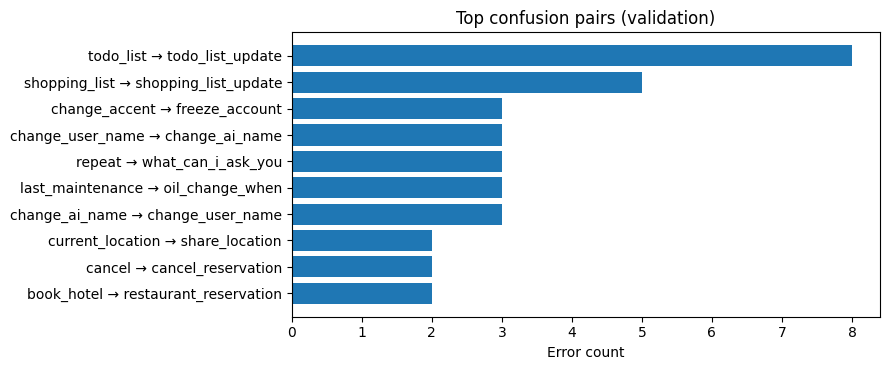

Representative errors (first example for each top pair)


,source_id,text,true_intent,predicted_intent
0,clinc_validation_360,will you start calling me chaz,change_user_name,change_ai_name
3,clinc_validation_865,what did you just ask,repeat,what_can_i_ask_you
6,clinc_validation_1486,did i put cutting the grass on my todo list,todo_list,todo_list_update
14,clinc_validation_1513,help me change my account,change_accent,freeze_account
17,clinc_validation_2014,when did i change my oil,last_maintenance,oil_change_when
20,clinc_validation_2136,can you make a reservation in tampa from may 2...,book_hotel,restaurant_reservation
22,clinc_validation_2144,pass me my gps coordinates,current_location,share_location
24,clinc_validation_2243,whats the procedure to cancel it,cancel,cancel_reservation
26,clinc_validation_2525,did i add salt to my shopping list,shopping_list,shopping_list_update
31,clinc_validation_2782,i want to call you maggie,change_ai_name,change_user_name


,metric,value
0,dataset,clinc150
1,method,lora
2,seed,42
3,shot_budget,None
4,sampling_mode,independent
5,backbone,roberta-base
6,gpu,NVIDIA GeForce RTX 5060 Laptop GPU
7,train_size,14995
8,validation_size,3000
9,test_size,4500


In [7]:
if trained is None:
    raise RuntimeError("Run the training cell for the current model before evaluating.")
validation_result = evaluate_model(model, val_ds, val_frame, val_y, "validation")
display_results(validation_result)
test_result = None
if FINAL_TEST:
    test_frame = protocol["test"]
    test_y = test_frame["label"].map(original_to_class).to_numpy(dtype=np.int64)
    test_ds = df_to_hf_dataset(test_frame, tokenizer, test_y)
    test_result = evaluate_model(model, test_ds, test_frame, test_y, "test")
    display_results(test_result)

metrics = {
    "dataset": DATASET, "method": METHOD, "seed": SEED, "shot_budget": SHOT_BUDGET,
    "sampling_mode": SAMPLING_MODE, "backbone": BACKBONE, "gpu": GPU_NAME,
    "train_size": len(train_ds), "validation_size": len(val_ds), "test_size": len(protocol["test"]),
    "validation_accuracy": validation_result["accuracy"], "validation_macro_f1": validation_result["macro_f1"],
    "test_accuracy": test_result["accuracy"] if test_result else None,
    "test_macro_f1": test_result["macro_f1"] if test_result else None,
    "prediction_seconds": validation_result["prediction_seconds"],
    "prediction_peak_allocated_mib": validation_result["prediction_peak_allocated_mib"],
    "test_prediction_seconds": test_result["prediction_seconds"] if test_result else None,
    "test_prediction_peak_allocated_mib": test_result["prediction_peak_allocated_mib"] if test_result else None,
    "trainable_parameters": trainable_parameters, "total_parameters": total_parameters,
    "trainable_parameter_pct": parameter_percent, **trained, "versions": VERSIONS,
    "protocol_meta": protocol["protocol_meta"],
}
display(pd.DataFrame([{"metric": key, "value": value} for key, value in metrics.items()
                      if key not in {"training_settings", "versions", "protocol_meta"}]))
